# 05 - PyTorch basics

1. **Tensors**: shapes, dtypes, and how they relate to NumPy arrays.
2. **Autograd**: how PyTorch computes gradients for you.
3. **The training loop**: model, loss, optimiser, and the five steps that repeat.
4. **`nn.Module`**: how to define a model.
5. **Devices**: moving work to a GPU, and writing code that also runs without one.
6. **`Dataset` and `DataLoader`**: feeding data in batches, using our own PCA pixels from notebook 04.
7. **Save and reload** a trained model.

**Requires:** notebook 04 has been run, so `data/processed/mock_pca.npz` exists.

## 1. Tensors

A **tensor** is a NumPy-like array with two extras: it can live on a **GPU**, and it can **track gradients**. Most of what you know from NumPy carries over; the names differ a little:

| NumPy | PyTorch |
|---|---|
| `axis=0` | `dim=0` |
| `np.transpose(a, (2, 0, 1))` | `t.permute(2, 0, 1)` |
| `a.reshape(...)` | `t.reshape(...)` / `t.view(...)` |
| `a.astype(np.float32)` | `t.float()` or `t.to(torch.float32)` |

Three things to check on **every** tensor you debug: `.shape`, `.dtype`, `.device`.

In [10]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(0)
np.random.seed(0)
plt.rcParams["figure.dpi"] = 110

REPO_ROOT = Path(".") if Path("notebooks").is_dir() else Path("..")
FIG_DIR = REPO_ROOT / "reports" / "figures"
MODEL_DIR = REPO_ROOT / "models"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print("saved", FIG_DIR / name)


print("torch", torch.__version__)

a = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
print("shape:", a.shape, "| dtype:", a.dtype, "| device:", a.device)

# default dtypes: floats are float32, integers are int64
print("zeros:", torch.zeros(2, 3).dtype, "| arange:", torch.arange(6).dtype, "| [1, 2]:", torch.tensor([1, 2]).dtype)

torch 2.15.0+cpu
shape: torch.Size([2, 3]) | dtype: torch.float32 | device: cpu
zeros: torch.float32 | arange: torch.int64 | [1, 2]: torch.int64


### NumPy and PyTorch share memory (careful!)

`torch.from_numpy(arr)` does **not** copy: the tensor and the array are two views of the same numbers. Change one and the other changes. `torch.tensor(arr)` makes a real copy.

Also watch the dtype: NumPy creates `float64` by default, but models use `float32`. A `float64` tensor going into a `float32` model is one of the most common PyTorch errors.

In [11]:
arr = np.arange(6, dtype=np.float32).reshape(2, 3)

t = torch.from_numpy(arr)          # shares memory
t[0, 0] = 100
print("numpy array changed too   :", arr[0, 0])

t_copy = torch.tensor(arr)         # independent copy
t_copy[0, 0] = -1
print("original after editing the copy:", arr[0, 0], "(still 100: the copy is independent)")

# the dtype trap
x64 = torch.from_numpy(np.random.rand(2, 3))       # float64, because NumPy defaults to float64
print()
print("from a default NumPy array:", x64.dtype, "-> convert with .float():", x64.float().dtype)
try:
    torch.randn(2, 3) @ torch.randn(3, 2, dtype=torch.float64)
except RuntimeError as err:
    print("mixing float32 and float64 fails:", str(err)[:70])

numpy array changed too   : 100.0
original after editing the copy: 100.0 (still 100: the copy is independent)

from a default NumPy array: torch.float64 -> convert with .float(): torch.float32
mixing float32 and float64 fails: expected m1 and m2 to have the same dtype, but got: float != double


### Shapes: permute, views and broadcasting

Our PCA scores are `(H, W, K)`, but PyTorch convolutions expect **channels first**: `(K, H, W)`. `permute` does this without copying (a *view*), exactly like `np.transpose` in notebook 01.

**Broadcasting** works as in NumPy: a `(1, 3)` row can be subtracted from a `(4, 3)` matrix. `keepdim=True` keeps the reduced axis as size 1, which is what makes the subtraction line up.

In [12]:
scores = torch.rand(67, 67, 10)                    # (H, W, K), like our PCA scores
chw = scores.permute(2, 0, 1)                      # (K, H, W)
print("permuted:", tuple(chw.shape), "| mean over dim 0:", tuple(chw.mean(dim=0).shape))
print("contiguous after permute:", chw.is_contiguous(), "-> after .contiguous():", chw.contiguous().is_contiguous())

x = torch.randn(4, 3)
mu = x.mean(dim=0, keepdim=True)                   # (1, 3)
print()
print("x - mu shape:", tuple((x - mu).shape), "| column means after centring:", (x - mu).mean(dim=0).abs().max().item() < 1e-6)

batch = torch.rand(8, 10, 5, 5)                    # (batch, channels, H, W): the shape CNNs use
print("a batch of 8 patches, 10 channels, 5 x 5 pixels:", tuple(batch.shape))

permuted: (10, 67, 67) | mean over dim 0: (67, 67)
contiguous after permute: False -> after .contiguous(): True

x - mu shape: (4, 3) | column means after centring: True
a batch of 8 patches, 10 channels, 5 x 5 pixels: (8, 10, 5, 5)


## 2. Autograd

Mark a tensor with `requires_grad=True` and PyTorch records every operation on it. Calling `.backward()` on the result computes the **gradient** (the slope of the result with respect to each tracked tensor) and stores it in `.grad`.

Example: `y = x * w**2` with `x = 3`, `w = 2`. The slope with respect to `w` is `2 * x * w = 12`.

Two rules to remember:

- Gradients **accumulate**: a second `.backward()` adds to `.grad` instead of replacing it. That is why every training step starts with `zero_grad()`.
- Inside `torch.no_grad()` nothing is tracked. Use it for evaluation and prediction: it is faster and uses less memory.

In [13]:
w = torch.tensor(2.0, requires_grad=True)
x = torch.tensor(3.0)

y = x * w ** 2
y.backward()
print("dy/dw =", w.grad.item(), "(expected 2 * 3 * 2 = 12)")

y = x * w ** 2
y.backward()
print("after a second backward:", w.grad.item(), "<- accumulated (12 + 12), not replaced")
w.grad.zero_()

with torch.no_grad():
    z = x * w ** 2
print("tracked inside no_grad?", z.requires_grad)

dy/dw = 12.0 (expected 2 * 3 * 2 = 12)
after a second backward: 24.0 <- accumulated (12 + 12), not replaced
tracked inside no_grad? False


## 3. Learning by gradient descent, first by hand, then the PyTorch way

**Task:** recover the line `y = 3x + 1` from 100 noisy points. The idea behind all neural network training:

1. make a prediction,
2. measure the error (the **loss**),
3. compute the gradient of the loss with respect to every parameter,
4. nudge each parameter a little **against** its gradient.

First with plain tensors and a hand-written update.

In [14]:
x = torch.linspace(-1, 1, 100).unsqueeze(1)                 # (100, 1)
y_true = 3 * x + 1 + 0.1 * torch.randn_like(x)              # noisy line

w = torch.zeros(1, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
lr = 0.1

for step in range(100):
    pred = x @ w + b
    loss = ((pred - y_true) ** 2).mean()
    loss.backward()
    with torch.no_grad():                                   # the update itself must not be tracked
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_()
    b.grad.zero_()

print(f"by hand : w = {w.item():.2f}, b = {b.item():.2f}  (true values: 3 and 1), final loss {loss.item():.4f}")

by hand : w = 3.03, b = 1.00  (true values: 3 and 1), final loss 0.0095


Now the same task with PyTorch's building blocks. This is the **standard pattern** you will reuse for every model in this project:

- `nn.Linear` holds the parameters (`w` and `b`),
- a **loss function** (`nn.MSELoss`) measures the error,
- an **optimiser** (`torch.optim.SGD`) performs the update step,
- the loop is always: `zero_grad` -> forward -> loss -> `backward` -> `step`.

In [15]:
model = nn.Linear(1, 1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

for step in range(100):
    optimizer.zero_grad()                  # 1. clear old gradients
    loss = loss_fn(model(x), y_true)       # 2. forward pass and loss
    loss.backward()                        # 3. gradients
    optimizer.step()                       # 4. update the parameters

print(f"PyTorch : w = {model.weight.item():.2f}, b = {model.bias.item():.2f}, final loss {loss.item():.4f}")

PyTorch : w = 3.03, b = 1.00, final loss 0.0095


## 4. Defining a model with `nn.Module`

A model is a class with two parts:

- `__init__` creates the layers (these hold the learnable parameters),
- `forward` says how data flows through them.

We build the small classifier we will train on our PCA pixels: **10 PCA scores in, one number out**. That number is a **logit** (a raw score): large and positive means "stressed", large and negative means "healthy". `sigmoid(logit)` turns it into a probability.

`model.train()` and `model.eval()` switch layers such as Dropout and BatchNorm between training and prediction behaviour. Our tiny MLP has neither, but the 3D-CNN will, so we build the habit of always calling them.

In [16]:
class PixelMLP(nn.Module):
    def __init__(self, n_features, hidden=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),          # ONE output: the logit of "stressed"
        )

    def forward(self, x):
        return self.net(x).squeeze(1)      # (batch, 1) -> (batch,)


demo = PixelMLP(10)
print(demo)
print("learnable parameters:", sum(p.numel() for p in demo.parameters()))

out = demo(torch.randn(5, 10))
print("output shape for a batch of 5:", tuple(out.shape), "| probabilities:", torch.sigmoid(out).detach().numpy().round(2))
print("training mode:", demo.training, "-> after .eval():", demo.eval().training)

PixelMLP(
  (net): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
learnable parameters: 193
output shape for a batch of 5: (5,) | probabilities: [0.54 0.55 0.51 0.51 0.52]
training mode: True -> after .eval(): False


## 5. Devices: CPU and GPU

A GPU does thousands of small calculations at once, which is what neural networks need. A tensor lives on **one** device, and operations only work between tensors on the **same** device.

Write **device-agnostic** code: pick a device once, then follow three rules everywhere:

1. `model.to(device)` once, after creating the model.
2. `.to(device)` on every batch of data inside the loop.
3. `.cpu()` before converting a result to NumPy or plotting it.

On a machine without a GPU the same code simply runs on the CPU. Our mock data is tiny, so that is fine; the GPU matters from the real potato data onward.

In [17]:
if torch.cuda.is_available():
    device = torch.device("cuda")          # NVIDIA GPU
elif torch.backends.mps.is_available():
    device = torch.device("mps")           # Apple silicon
else:
    device = torch.device("cpu")

print("using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


def sync(dev):
    # GPU calls are asynchronous: wait for them to finish before reading the clock
    if dev.type == "cuda":
        torch.cuda.synchronize()
    elif dev.type == "mps":
        torch.mps.synchronize()


def time_matmul(dev, n=2000, repeats=10):
    a = torch.randn(n, n, device=dev)
    b = torch.randn(n, n, device=dev)
    _ = a @ b                              # warm-up call
    sync(dev)
    start = time.perf_counter()
    for _ in range(repeats):
        _ = a @ b
    sync(dev)
    return (time.perf_counter() - start) / repeats


cpu_time = time_matmul(torch.device("cpu"))
print(f"2000 x 2000 matrix multiply on cpu: {cpu_time * 1000:.1f} ms")

if device.type != "cpu":
    dev_time = time_matmul(device)
    print(f"2000 x 2000 matrix multiply on {device.type}: {dev_time * 1000:.1f} ms  ({cpu_time / dev_time:.0f}x faster)")
    try:
        torch.randn(2, 2, device=device) @ torch.randn(2, 2)      # one tensor on each device
    except RuntimeError as err:
        print("mixing devices fails:", str(err)[:80])
else:
    print("no GPU found: everything below runs on the CPU")

using device: cpu
2000 x 2000 matrix multiply on cpu: 191.8 ms
no GPU found: everything below runs on the CPU


## 6. `Dataset` and `DataLoader`

Training never feeds the whole dataset at once. A **`Dataset`** answers two questions, "how many samples?" (`__len__`) and "give me sample *i*" (`__getitem__`). A **`DataLoader`** wraps a Dataset and hands out **batches**, optionally shuffled each epoch.

We use the PCA scores from notebook 04: every valid pixel is one sample with 10 features, and the label says healthy (0) or stressed (1).

**Important about the numbers below:** the mock cube has only **21 stressed pixels out of 4,489**. Always check the class balance first. If a model says "healthy" for every pixel it is already 99.5% accurate and has learned nothing, so accuracy alone is a trap. We look at **recall and precision on the stressed class** instead.

In [18]:
npz_path = REPO_ROOT / "data" / "processed" / "mock_pca.npz"
assert npz_path.exists(), "run notebook 04 first to create mock_pca.npz"

data = np.load(npz_path)
scores_np, labels_np, valid_np = data["scores"], data["labels"], data["valid"]
K = scores_np.shape[-1]

X_all = scores_np[valid_np]            # (n_pixels, K)  one row per valid pixel
y_all = labels_np[valid_np]            # (n_pixels,)
print("samples:", X_all.shape, "| stressed:", int(y_all.sum()), "| healthy:", int((y_all == 0).sum()))
print(f"accuracy of a model that always says 'healthy': {(y_all == 0).mean():.2%}")

samples: (4489, 10) | stressed: 21 | healthy: 4468
accuracy of a model that always says 'healthy': 99.53%


### A demo split, with a warning

We split pixels into 80% train and 20% validation, **keeping the same healthy/stressed ratio in both** (stratified). We then normalise the features with the **training** mean and std only, so nothing from the validation pixels leaks in.

**This random pixel split is only for practising the loop.** Neighbouring pixels are almost copies of each other, so a random split makes validation look easier than reality. With only 5 stressed pixels in validation, the numbers are also very rough. The proper **spatial split** (train and validation in different parts of the field) comes on Thu 19 Nov.

In [19]:
rng = np.random.default_rng(0)
idx_healthy = rng.permutation(np.where(y_all == 0)[0])
idx_stressed = rng.permutation(np.where(y_all == 1)[0])


def split(idx, frac=0.8):
    cut = int(len(idx) * frac)
    return idx[:cut], idx[cut:]


train_h, val_h = split(idx_healthy)
train_s, val_s = split(idx_stressed)
train_idx = np.concatenate([train_h, train_s])
val_idx = np.concatenate([val_h, val_s])
print(f"train: {len(train_idx)} pixels ({len(train_s)} stressed) | validation: {len(val_idx)} pixels ({len(val_s)} stressed)")

mu = X_all[train_idx].mean(axis=0)                 # statistics from the TRAINING pixels only
sd = X_all[train_idx].std(axis=0) + 1e-8
X_norm = ((X_all - mu) / sd).astype(np.float32)


class PixelDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()       # float32 features
        self.y = torch.from_numpy(y).float()       # the loss wants float targets

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return self.X[i], self.y[i]


train_ds = PixelDataset(X_norm[train_idx], y_all[train_idx])
val_ds = PixelDataset(X_norm[val_idx], y_all[val_idx])

train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)       # shuffle only for training
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False)

xb, yb = next(iter(train_loader))
print("one batch:", tuple(xb.shape), xb.dtype, "| labels:", tuple(yb.shape), yb.dtype)
print("batches per epoch:", len(train_loader))

train: 3590 pixels (16 stressed) | validation: 899 pixels (5 stressed)
one batch: (256, 10) torch.float32 | labels: (256,) torch.float32
batches per epoch: 15


## 7. The training and evaluation loops

Two functions, written once and reused all project:

- **`train_one_epoch`**: for each batch, the five steps `zero_grad -> forward -> loss -> backward -> step`.
- **`evaluate`**: the same forward pass, but under `torch.no_grad()` and `model.eval()`, and **no** weight update.

**The loss.** `BCEWithLogitsLoss` is the standard loss for a yes/no label with one logit output. Because stressed pixels are so rare, we pass `pos_weight` (healthy count divided by stressed count): each stressed pixel then counts as much as about 220 healthy ones, so the stressed class as a whole weighs as much as the healthy class and the model cannot win by ignoring it.

A **prediction** is `logit > 0`, which is the same as probability above 0.5.

In [20]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):
    model.train()
    total, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)       # rule 2: every batch goes to the device
        optimizer.zero_grad()                       # 1. clear old gradients
        logits = model(xb)                          # 2. forward pass
        loss = loss_fn(logits, yb)                  # 3. how wrong are we?
        loss.backward()                             # 4. gradients of the loss
        optimizer.step()                            # 5. update the weights
        total += loss.item() * len(xb)
        n += len(xb)
    return total / n


@torch.no_grad()
def evaluate(model, loader, loss_fn, device):
    model.eval()
    total, n = 0.0, 0
    preds, trues = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        total += loss_fn(logits, yb).item() * len(xb)
        n += len(xb)
        preds.append((logits > 0).long().cpu())     # rule 3: back to the CPU before using results
        trues.append(yb.long().cpu())
    return total / n, torch.cat(preds), torch.cat(trues)


def stressed_metrics(pred, true):
    tp = int(((pred == 1) & (true == 1)).sum())
    fp = int(((pred == 1) & (true == 0)).sum())
    fn = int(((pred == 0) & (true == 1)).sum())
    tn = int(((pred == 0) & (true == 0)).sum())
    return dict(tp=tp, fp=fp, fn=fn, tn=tn,
                accuracy=(tp + tn) / len(true),
                precision=tp / max(tp + fp, 1),
                recall=tp / max(tp + fn, 1))

### Sanity check: can the model overfit one small batch?

Before any real training, take one small batch and train on it repeatedly. A correct model, loss and loop will push that batch's loss close to zero. If it cannot, there is a bug (wrong shapes, wrong dtype, missing `zero_grad`...), and it is much easier to find it here than after an hour of training.

In [21]:
torch.manual_seed(0)
n_stressed_train = int(y_all[train_idx].sum())
pos_weight = torch.tensor((len(train_idx) - n_stressed_train) / n_stressed_train, device=device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print(f"pos_weight = {pos_weight.item():.0f}")

small_model = PixelMLP(K).to(device)
small_opt = torch.optim.Adam(small_model.parameters(), lr=0.01)
xb, yb = next(iter(train_loader))
xb, yb = xb[:32].to(device), yb[:32].to(device)

for step in range(201):
    small_opt.zero_grad()
    loss = loss_fn(small_model(xb), yb)
    loss.backward()
    small_opt.step()
    if step % 50 == 0:
        print(f"step {step:>3}  loss {loss.item():.4f}")

pos_weight = 223


step   0  loss 0.6502
step  50  loss 0.0136
step 100  loss 0.0026
step 150  loss 0.0013
step 200  loss 0.0008


### The real training run

30 epochs. After every epoch we record the training and validation loss. Watch both: training loss falling while validation loss rises would mean **overfitting**.

epoch  1  train loss 1.0341  val loss 0.7485
epoch  5  train loss 0.1070  val loss 0.0945
epoch 10  train loss 0.0140  val loss 0.0167
epoch 15  train loss 0.0060  val loss 0.0083
epoch 20  train loss 0.0034  val loss 0.0053
epoch 25  train loss 0.0022  val loss 0.0038
epoch 30  train loss 0.0016  val loss 0.0030

validation, stressed class: {'tp': 5, 'fp': 0, 'fn': 0, 'tn': 894, 'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0}
for comparison, 'always healthy' accuracy would be 99.44%
saved ..\reports\figures\pytorch_loss_curves.png


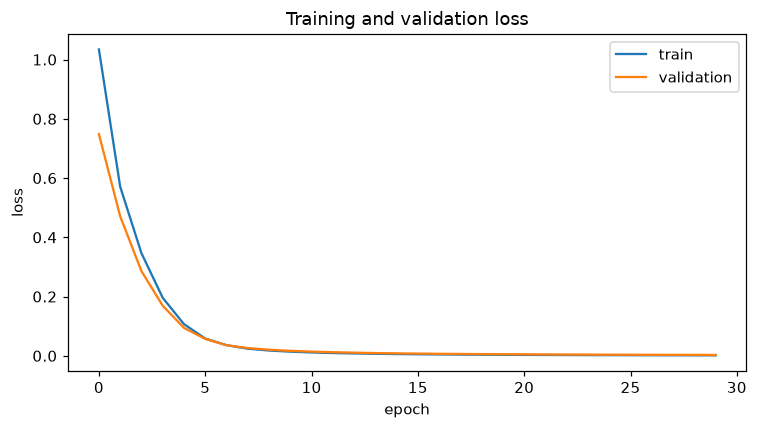

In [22]:
torch.manual_seed(0)
model = PixelMLP(K).to(device)                                  # rule 1: model to the device, once
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

history = {"train": [], "val": []}
for epoch in range(1, 31):
    train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer, device)
    val_loss, pred, true = evaluate(model, val_loader, loss_fn, device)
    history["train"].append(train_loss)
    history["val"].append(val_loss)
    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:>2}  train loss {train_loss:.4f}  val loss {val_loss:.4f}")

m = stressed_metrics(pred, true)
print()
print("validation, stressed class:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in m.items()})
print(f"for comparison, 'always healthy' accuracy would be {(true == 0).float().mean().item():.2%}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history["train"], label="train")
ax.plot(history["val"], label="validation")
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.set_title("Training and validation loss")
ax.legend()
fig.tight_layout()
save_fig(fig, "pytorch_loss_curves.png")
plt.show()

**How to read the result.** The mock cube was designed with a clear stress signal (PCA notebook: components 1 and 2 separate the classes by a wide margin), so this task is easy and the loop reaches high recall. That is the point of this notebook: the **mechanics** work. The validation numbers rest on only a few stressed pixels and a leaky random split, so do not quote them as results. The honest evaluation comes on Thu 19.

## 8. Save and reload a model

`model.state_dict()` is a plain dictionary of all learned parameters. We save it **together with the normalisation numbers** (`mu`, `sd`), because the model is useless without them: new data must be normalised exactly as the training data was.

After saving, always reload into a fresh model and check it gives **identical** outputs. `weights_only=True` makes `torch.load` accept only tensors and plain Python values, which is the safe way to load files.

In [23]:
ckpt_path = MODEL_DIR / "pixel_mlp.pt"
torch.save(
    {"state_dict": model.state_dict(), "n_features": K,
     "mu": torch.from_numpy(mu), "sd": torch.from_numpy(sd)},
    ckpt_path,
)
print(f"{ckpt_path.name}: {ckpt_path.stat().st_size / 1e3:.1f} KB")

ckpt = torch.load(ckpt_path, map_location=device, weights_only=True)
reloaded = PixelMLP(ckpt["n_features"]).to(device)
reloaded.load_state_dict(ckpt["state_dict"])
reloaded.eval()
model.eval()

xb, _ = next(iter(val_loader))
xb = xb.to(device)
with torch.no_grad():
    same = torch.allclose(model(xb), reloaded(xb))
print("reloaded model gives identical outputs:", same)

pixel_mlp.pt: 3.8 KB
reloaded model gives identical outputs: True


## Takeaways

- A tensor is an array with a **shape, dtype and device**; check all three when something breaks. `from_numpy` shares memory, and NumPy's default `float64` must become `float32` for models.
- **Autograd** records operations and `.backward()` fills `.grad`. Gradients accumulate, so call `zero_grad()` every step. Use `torch.no_grad()` for evaluation.
- Every training loop is the same five steps: **`zero_grad` -> forward -> loss -> `backward` -> `step`**.
- A model is an `nn.Module` with `__init__` (layers) and `forward` (data flow). Call `.train()` / `.eval()`.
- **Device-agnostic code**: pick the device once, `model.to(device)` once, `.to(device)` per batch, `.cpu()` before NumPy.
- `Dataset` = how many samples + give me sample *i*; `DataLoader` = batches and shuffling.
- **Check class balance first**, and never trust accuracy alone on rare classes.
- Overfit one small batch as a bug check, and always **reload what you saved** and compare.

**Next (Wed 18 Nov plan):** 3D convolutions, a HybridSN-style model and patch extraction.